# Real-World Dataset Analysis Project
**Dataset:** Breast Cancer Wisconsin (Diagnostic)

An end-to-end analysis: dataset selection, exploration, cleaning, exploratory data analysis, visualisation, and interpretation.

> This project is for learning data analysis. It is not a medical tool and its results must not be used for diagnosis.

## 1. Dataset Selection and Context
- **Source:** UCI Machine Learning Repository, *Breast Cancer Wisconsin (Diagnostic)* dataset, created by W. H. Wolberg, W. N. Street and O. L. Mangasarian (University of Wisconsin). A copy is bundled with scikit-learn, so the notebook runs without a download.
- **Context:** each row is one breast mass. Features were computed from digitised images of a fine needle aspirate (FNA) and describe the cell nuclei in the image. Each mass is labelled **malignant** or **benign**.
- **Variables:** 30 numeric features made from 10 measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension). Each is given as a *mean*, a *standard error* and a *worst* (largest) value.
- **Why this dataset:** it is a well-known, reliable real-world dataset with a clear analytical goal.

**Questions to answer**
1. How do malignant and benign masses differ in their measurements?
2. Which features are most strongly linked to a malignant diagnosis?
3. Are the features redundant with each other?
4. Which data-quality issues need attention before analysis?

## 2. Setup and Loading the Data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.datasets import load_breast_cancer

sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)
np.random.seed(42)
COLORS = {"Malignant": "tab:red", "Benign": "tab:blue"}

raw = load_breast_cancer(as_frame=True)
df_raw = raw.frame.copy()
print("Shape:", df_raw.shape)
print("Target meaning (0, 1):", [str(n) for n in raw.target_names])
print(df_raw.iloc[:5, [0, 1, 3, 6, 30]].to_string())

Shape: (569, 31)
Target meaning (0, 1): ['malignant', 'benign']
   mean radius  mean texture  mean area  mean concavity  target
0        17.99         10.38     1001.0          0.3001       0
1        20.57         17.77     1326.0          0.0869       0
2        19.69         21.25     1203.0          0.1974       0
3        11.42         20.38      386.1          0.2414       0
4        20.29         14.34     1297.0          0.1980       0


## 3. Exploring the Dataset

In [2]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [3]:
print("Missing values:", int(df_raw.isnull().sum().sum()))
print("Duplicate rows:", int(df_raw.duplicated().sum()))
print()
counts = df_raw["target"].map({0: "Malignant", 1: "Benign"}).value_counts()
print(counts.to_string())
print((counts / counts.sum() * 100).round(1).to_string())
print()
print(df_raw[["mean radius", "mean texture", "mean area", "mean concavity"]].describe().round(2).to_string())

Missing values: 0
Duplicate rows: 0

target
Benign       357
Malignant    212
target
Benign       62.7
Malignant    37.3

       mean radius  mean texture  mean area  mean concavity
count       569.00        569.00     569.00          569.00
mean         14.13         19.29     654.89            0.09
std           3.52          4.30     351.91            0.08
min           6.98          9.71     143.50            0.00
25%          11.70         16.17     420.30            0.03
50%          13.37         18.84     551.10            0.06
75%          15.78         21.80     782.70            0.13
max          28.11         39.28    2501.00            0.43


## 4. Data Cleaning and Preprocessing
Each objective check is run, and a decision is made for every issue found. The dataset was prepared carefully by its authors, so several checks come back clean. Those results are still reported, because confirming that data is clean is part of the process.

In [4]:
df = df_raw.copy()

# 4.1 Consistent column names
df.columns = df.columns.str.replace(" ", "_")

# 4.2 Correct data types and readable labels (in the original data 0 = malignant, 1 = benign)
df["diagnosis"] = df["target"].map({0: "Malignant", 1: "Benign"}).astype("category")
df["malignant"] = (df["target"] == 0).astype(int)
df = df.drop(columns="target")

# 4.3 Missing values and duplicates
print("Missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

# 4.4 Validity checks: size measurements must be positive
size_cols = [c for c in df.columns if any(k in c for k in ["radius", "area", "perimeter", "texture"])]
print("Non-positive size values:", int((df[size_cols] <= 0).sum().sum()))
print("Data types:", df.dtypes.astype(str).value_counts().to_dict())

Missing values: 0
Duplicate rows: 0
Non-positive size values: 0
Data types: {'float64': 30, 'category': 1, 'int64': 1}


In [5]:
# 4.5 Outlier detection with the IQR rule
num = df.drop(columns=["diagnosis", "malignant"])
q1, q3 = num.quantile(0.25), num.quantile(0.75)
iqr = q3 - q1
is_out = (num < q1 - 1.5 * iqr) | (num > q3 + 1.5 * iqr)

print("Features with the most outliers:")
print(is_out.sum().sort_values(ascending=False).head(6).to_string())
rows_out = is_out.any(axis=1)
print(f"\nRows with at least one outlier: {rows_out.sum()} ({rows_out.mean() * 100:.1f}%)")
share = (rows_out.groupby(df["diagnosis"], observed=True).mean() * 100).round(1)
print("\nShare of rows with an outlier, by diagnosis (%):")
print(share.to_string())

Features with the most outliers:
area_error                 65
radius_error               38
perimeter_error            38
worst_area                 35
smoothness_error           30
fractal_dimension_error    28

Rows with at least one outlier: 171 (30.1%)

Share of rows with an outlier, by diagnosis (%):
diagnosis
Benign       16.0
Malignant    53.8


In [6]:
# 4.6 Decision on outliers: they are KEPT, because they are mostly large tumours that are
# medically meaningful, not data-entry errors. Removing them would delete the malignant cases.
# 4.7 Skewed features: a log transform reduces skewness
print("Most skewed features:")
print(num.skew().sort_values(ascending=False).head(5).round(2).to_string())
df["log_mean_area"] = np.log1p(df["mean_area"])
print(f"\nSkewness of mean_area: {df['mean_area'].skew():.2f} -> after log transform: {df['log_mean_area'].skew():.2f}")
print("\nCleaned dataset shape:", df.shape)

Most skewed features:
area_error                 5.45
concavity_error            5.11
fractal_dimension_error    3.92
perimeter_error            3.44
radius_error               3.09

Skewness of mean_area: 1.65 -> after log transform: 0.29

Cleaned dataset shape: (569, 33)


## 5. Exploratory Data Analysis

In [7]:
mean_cols = [c for c in df.columns if c.startswith("mean_")]

grp = df.groupby("diagnosis", observed=True)[mean_cols].mean().T.round(3)
grp["ratio"] = (grp["Malignant"] / grp["Benign"]).round(2)
print("Average of each 'mean' feature by diagnosis:")
print(grp.to_string())

Average of each 'mean' feature by diagnosis:
diagnosis                Benign  Malignant  ratio
mean_radius              12.147     17.463   1.44
mean_texture             17.915     21.605   1.21
mean_perimeter           78.075    115.365   1.48
mean_area               462.790    978.376   2.11
mean_smoothness           0.092      0.103   1.12
mean_compactness          0.080      0.145   1.81
mean_concavity            0.046      0.161   3.50
mean_concave_points       0.026      0.088   3.38
mean_symmetry             0.174      0.193   1.11
mean_fractal_dimension    0.063      0.063   1.00


In [8]:
# Welch t-test: is the difference between the two groups statistically significant?
rows = []
for c in mean_cols:
    m = df.loc[df["malignant"] == 1, c]
    b = df.loc[df["malignant"] == 0, c]
    t, p = stats.ttest_ind(m, b, equal_var=False)
    rows.append({"feature": c, "t_statistic": round(t, 1), "p_value": f"{p:.1e}"})
ttests = pd.DataFrame(rows)
print(ttests.to_string(index=False))

               feature  t_statistic p_value
           mean_radius         22.2 1.7e-64
          mean_texture         11.0 3.0e-25
        mean_perimeter         22.9 1.0e-66
             mean_area         19.6 3.3e-52
       mean_smoothness          9.3 5.6e-19
      mean_compactness         15.8 9.6e-42
        mean_concavity         20.3 3.7e-58
   mean_concave_points         24.8 3.1e-71
         mean_symmetry          8.1 6.0e-15
mean_fractal_dimension         -0.3 7.7e-01


In [9]:
# Correlation of every feature with a malignant diagnosis
corr_target = num.corrwith(df["malignant"]).sort_values(ascending=False)
print("Strongest positive correlations with malignancy:")
print(corr_target.head(6).round(2).to_string())
print("\nStrongest negative correlations:")
print(corr_target.tail(3).round(2).to_string())

# Redundancy: highly correlated pairs among the 'mean' features
cm = df[mean_cols].corr()
pairs = [(a, b, float(round(cm.loc[a, b], 2))) for i, a in enumerate(mean_cols) for b in mean_cols[i + 1:] if abs(cm.loc[a, b]) > 0.9]
print("\nPairs with |r| > 0.9:")
for p in pairs:
    print(p)

Strongest positive correlations with malignancy:
worst_concave_points    0.79
worst_perimeter         0.78
mean_concave_points     0.78
worst_radius            0.78
mean_perimeter          0.74
worst_area              0.73

Strongest negative correlations:
texture_error            -0.01
mean_fractal_dimension   -0.01
smoothness_error         -0.07

Pairs with |r| > 0.9:
('mean_radius', 'mean_perimeter', 1.0)
('mean_radius', 'mean_area', 0.99)
('mean_perimeter', 'mean_area', 0.99)
('mean_concavity', 'mean_concave_points', 0.92)


## 6. Visualisations

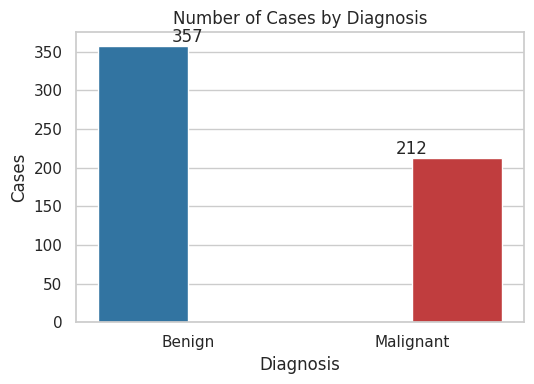

In [10]:
# 1. Bar chart: class distribution
cc = df["diagnosis"].value_counts()
plt.figure(figsize=(5.5, 4))
sns.barplot(x=cc.index, y=cc.values, hue=cc.index, palette=COLORS, legend=False)
for i, v in enumerate(cc.values):
    plt.text(i, v + 5, str(v), ha="center")
plt.title("Number of Cases by Diagnosis"); plt.xlabel("Diagnosis"); plt.ylabel("Cases")
plt.tight_layout(); plt.savefig("figures/01_bar_class_distribution.png", dpi=120); plt.show()

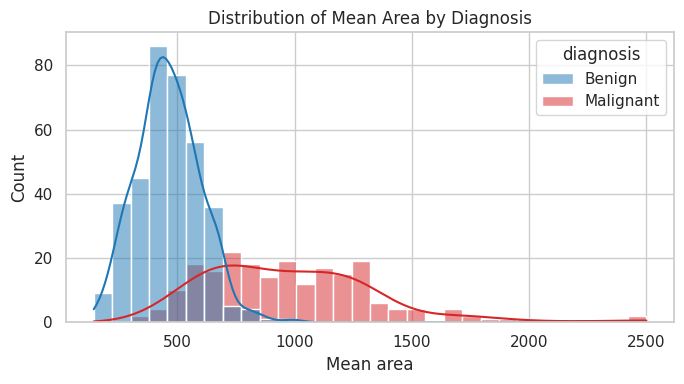

In [11]:
# 2. Histogram: distribution of mean area by diagnosis
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="mean_area", hue="diagnosis", bins=30, kde=True, palette=COLORS)
plt.title("Distribution of Mean Area by Diagnosis"); plt.xlabel("Mean area")
plt.tight_layout(); plt.savefig("figures/02_hist_mean_area.png", dpi=120); plt.show()

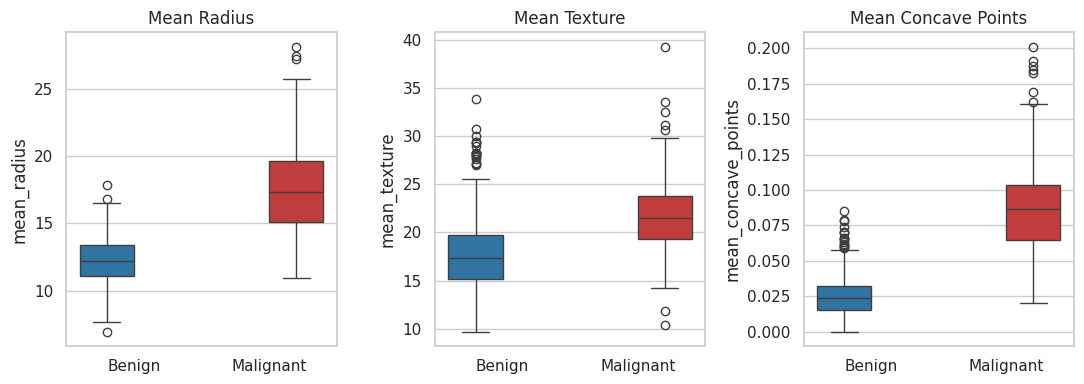

In [12]:
# 3. Box plots: key features by diagnosis
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
for ax, c in zip(axes, ["mean_radius", "mean_texture", "mean_concave_points"]):
    sns.boxplot(data=df, x="diagnosis", y=c, hue="diagnosis", palette=COLORS, legend=False, ax=ax)
    ax.set_title(c.replace("_", " ").title()); ax.set_xlabel("")
plt.tight_layout(); plt.savefig("figures/03_box_key_features.png", dpi=120); plt.show()

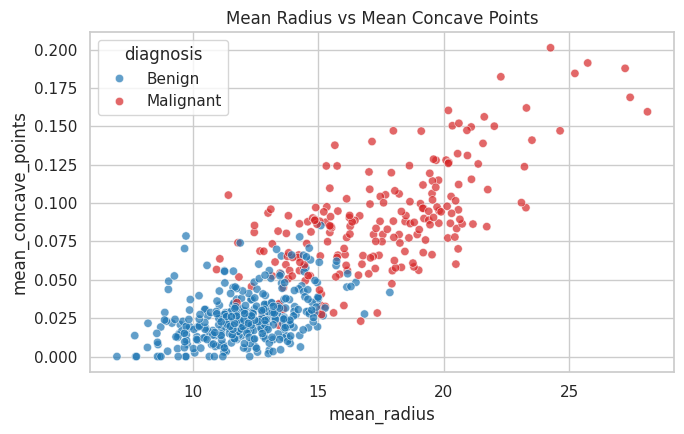

In [13]:
# 4. Scatter plot: radius vs concave points
plt.figure(figsize=(7, 4.5))
sns.scatterplot(data=df, x="mean_radius", y="mean_concave_points", hue="diagnosis", palette=COLORS, alpha=0.7)
plt.title("Mean Radius vs Mean Concave Points")
plt.tight_layout(); plt.savefig("figures/04_scatter_radius_concave.png", dpi=120); plt.show()

radius_decile
1       0.0
2       3.6
3       7.0
4       7.0
5      12.3
6      26.8
7      35.1
8      82.5
9      98.3
10    100.0


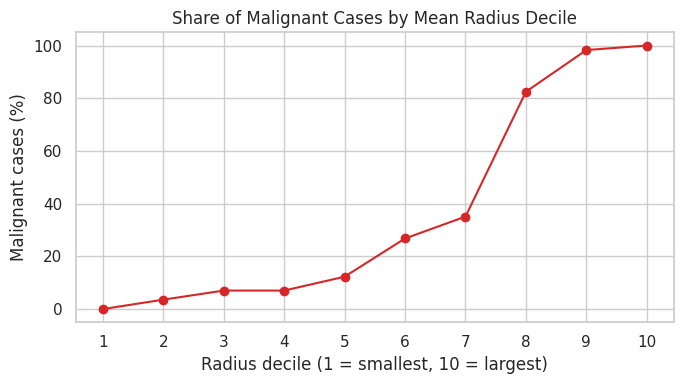

In [14]:
# 5. Line chart: malignancy rate across radius deciles (no time variable exists, so bins are used)
df["radius_decile"] = pd.qcut(df["mean_radius"], 10, labels=False) + 1
rate = df.groupby("radius_decile")["malignant"].mean() * 100
plt.figure(figsize=(7, 4))
plt.plot(rate.index, rate.values, marker="o", color="tab:red")
print(rate.round(1).to_string())
plt.xticks(range(1, 11))
plt.title("Share of Malignant Cases by Mean Radius Decile")
plt.xlabel("Radius decile (1 = smallest, 10 = largest)"); plt.ylabel("Malignant cases (%)")
plt.tight_layout(); plt.savefig("figures/05_line_malignancy_by_radius.png", dpi=120); plt.show()

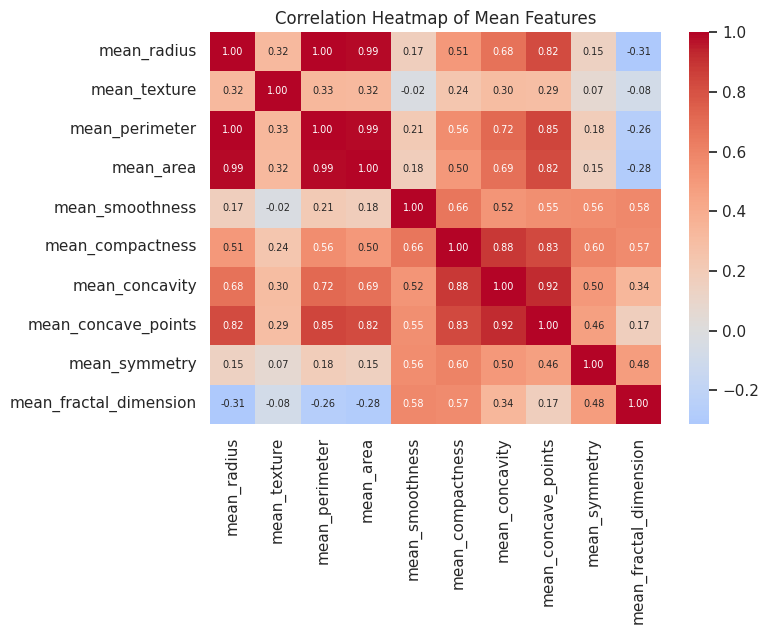

In [15]:
# 6. Heatmap: correlations among the 'mean' features
plt.figure(figsize=(8, 6.5))
sns.heatmap(df[mean_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation Heatmap of Mean Features")
plt.tight_layout(); plt.savefig("figures/06_heatmap_mean_features.png", dpi=120); plt.show()

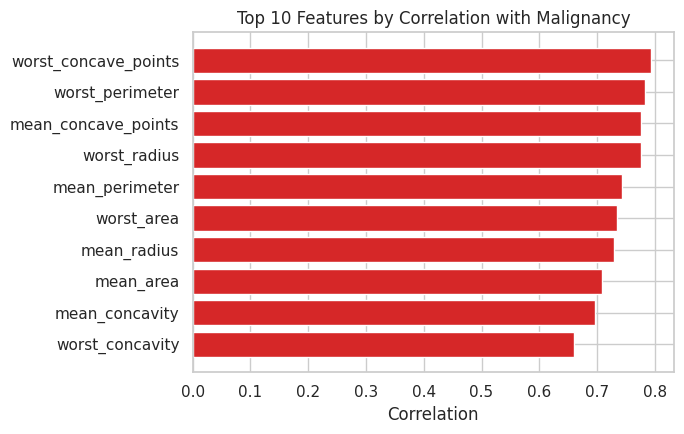

In [16]:
# 7. Bar chart: features most correlated with malignancy
top = corr_target.reindex(corr_target.abs().sort_values(ascending=False).index)[:10].sort_values()
plt.figure(figsize=(7, 4.5))
plt.barh(top.index, top.values, color=["tab:red" if v > 0 else "tab:blue" for v in top.values])
plt.title("Top 10 Features by Correlation with Malignancy"); plt.xlabel("Correlation")
plt.tight_layout(); plt.savefig("figures/07_bar_top_correlations.png", dpi=120); plt.show()

## 7. Supplementary Check: Baseline Classifier
A simple model shows whether the patterns found in the analysis are strong enough to separate the two groups. It is a sanity check, not a medical model.

In [17]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

X, y = num, df["malignant"]
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
res = cross_validate(model, X, y, cv=cv, scoring=["accuracy", "precision", "recall"])
for k in ["accuracy", "precision", "recall"]:
    s = res["test_" + k]
    print(f"{k.capitalize():<10}: {s.mean():.3f} (+/- {s.std():.3f})")

Accuracy  : 0.974 (+/- 0.017)
Precision : 0.986 (+/- 0.018)
Recall    : 0.944 (+/- 0.052)


## 8. Key Findings (computed)

In [18]:
top_feat = corr_target.abs().sort_values(ascending=False).index[0]
print(f"1. The dataset has {len(df)} cases: {cc['Benign']} benign and {cc['Malignant']} malignant ({cc['Malignant'] / len(df) * 100:.1f}% malignant).")
print(f"2. Malignant masses are larger: mean area is {grp.loc['mean_area', 'ratio']}x and mean radius {grp.loc['mean_radius', 'ratio']}x the benign average.")
print(f"3. Concavity shows the biggest relative gap: mean concavity is {grp.loc['mean_concavity', 'ratio']}x and mean concave points {grp.loc['mean_concave_points', 'ratio']}x the benign average.")
print(f"4. The feature most correlated with malignancy is {top_feat} (r = {corr_target[top_feat]:.2f}).")
print(f"5. Outliers appear in {share['Malignant']}% of malignant rows versus {share['Benign']}% of benign rows, so they carry real information.")
print(f"6. {len(pairs)} pairs of 'mean' features have |r| > 0.9, so many features are redundant.")
print(f"7. A simple logistic regression reaches {res['test_accuracy'].mean() * 100:.1f}% cross-validated accuracy and {res['test_recall'].mean() * 100:.1f}% recall for malignant cases.")

1. The dataset has 569 cases: 357 benign and 212 malignant (37.3% malignant).
2. Malignant masses are larger: mean area is 2.11x and mean radius 1.44x the benign average.
3. Concavity shows the biggest relative gap: mean concavity is 3.5x and mean concave points 3.38x the benign average.
4. The feature most correlated with malignancy is worst_concave_points (r = 0.79).
5. Outliers appear in 53.8% of malignant rows versus 16.0% of benign rows, so they carry real information.
6. 4 pairs of 'mean' features have |r| > 0.9, so many features are redundant.
7. A simple logistic regression reaches 97.4% cross-validated accuracy and 94.4% recall for malignant cases.


## 9. Observations, Interpretation and Recommendations

### Observations
- **Data quality:** the dataset has no missing values, duplicates or invalid values. The preprocessing work was renaming columns, labelling and typing the target, reviewing outliers and treating skewness.
- **Malignant masses are larger and more irregular:** average area is about 2.1 times higher, concavity about 3.5 times higher and concave points about 3.4 times higher than in benign masses.
- **Statistically significant differences:** nine of the ten mean features differ between the groups with very small p-values. Mean fractal dimension is the exception (p = 0.77), so it does not separate the groups.
- **Outliers carry information:** 53.8% of malignant rows contain an outlier compared with 16.0% of benign rows, so they were kept.
- **Redundant features:** radius, perimeter and area are almost perfectly correlated (r of 0.99 or higher), and concavity and concave points are correlated at 0.92.
- **Pattern across size:** the line chart shows the share of malignant cases rising from near zero in the smallest radius deciles to nearly all cases in the largest.

### Interpretation
Cell size, boundary irregularity and concavity are the clearest signals of malignancy in this data. The baseline logistic regression reached 97.4% cross-validated accuracy and 94.4% recall, which confirms that the patterns found in the analysis are strong. Recall varied by about 5 percentage points between folds, so the estimate is not precise. Correlation shows association only and does not explain the cause.

### Recommendations
1. Reduce redundancy with feature selection or regularisation, because many features carry the same information.
2. Keep outliers and use methods that handle them well, since they mostly represent real malignant cases.
3. In a real setting, prioritise recall for malignant cases and report a confusion matrix, because missing a malignant case is the costly error.
4. Validate on data from other hospitals before trusting any model built from this dataset.

### Limitations
The dataset has only 569 cases from one source, its features were pre-computed from images, and the analysis is for learning purposes, not for clinical use.

## 10. Conclusion
The project selected a reliable real-world dataset, explored and checked its quality, preprocessed it, analysed it statistically and visually, and interpreted the results. Malignant masses are clearly larger and more irregular than benign ones, and the strong signal is confirmed by a simple baseline model. The analysis is reproducible because the dataset is bundled with scikit-learn and the random seed is fixed.